# RAMS Analysis of a Passenger Train Fleet – 2. Exploratory Analysis
### Analyse RAMS d'une flotte de rames voyageurs – 2. Exploration et indicateurs RAMS

> **Données synthétiques**, générées pour l'exercice. Elles ne proviennent d'aucun exploitant réel.

**Données d'entrée :** `maintenance_rames_clean.csv`, produit par le notebook 1 (4 053 interventions, 30 rames, 8 systèmes, 2023-2025).

**Questions :**
1. **Fiabilité** : quels systèmes et quelles rames tombent le plus souvent en panne ?
2. **Maintenance préventive** : faut-il anticiper les visites pour réduire les pannes et l'immobilisation ?
3. **Organisation** : comment la maintenance (attente, charge des équipes) pèse-t-elle sur la disponibilité ?

**Résultats clés :**
- Les **portes** concentrent le plus d'heures perdues (≈ 25 % du total), à cause de leur fréquence de panne.
- **L'attente** (pièces, organisation) représente 60 à 90 % du temps d'arrêt, quel que soit le système.
- Deux **saisonnalités** : climatisation en été, freinage en hiver.
- Chaque système dépasse 99 % de disponibilité, mais **une rame tombe à ≈ 97,5 %** (≈ 9 jours d'arrêt par an).
- **Weibull** : aucune usure démontrée entre deux pannes (β ≈ 1).

**Plan :** 1. Vue d'ensemble · 2. Saisonnalité · 3. MTTR, MDT et attente · 4. Pareto · 5. MTBF · 6. Disponibilité · 7. Analyse par rame · 8. Charge des équipes · 9. Analyse de Weibull · 10. Synthèse

In [1]:
!pip install -q lifelines   # nécessaire pour l'analyse de Weibull (Internet activé sur Kaggle)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from lifelines import WeibullFitter
from scipy.special import gamma

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub


/kaggle/input/notebooks/oularealamako/railway-studies/__notebook__.ipynb
/kaggle/input/notebooks/oularealamako/railway-studies/__output__.json
/kaggle/input/notebooks/oularealamako/railway-studies/__results__.html
/kaggle/input/notebooks/oularealamako/railway-studies/custom.css
/kaggle/input/notebooks/oularealamako/railway-studies/maintenance_rames_clean.csv
/kaggle/input/notebooks/oularealamako/railway-studies/__results___files/__results___12_0.png
/kaggle/input/notebooks/oularealamako/railway-studies/__results___files/__results___13_0.png
/kaggle/input/notebooks/oularealamako/railway-studies/__results___files/__results___15_1.png
/kaggle/input/notebooks/oularealamako/railway-studies/__results___files/__results___26_0.png
/kaggle/input/notebooks/oularealamako/railway-studies/__results___files/__results___6_0.png
/kaggle/input/notebooks/oularealamako/railway-studies/__results___files/__results___7_0.png


In [ ]:
df = pd.read_csv("../data/maintenance_rames_clean.csv",
                 sep=";", decimal=",", parse_dates=["Date intervention"])

# Sous-ensemble des pannes (maintenance corrective), utilisé dans tout le notebook
cor = df[df["Type intervention"] == "corrective"].sort_values("Date intervention").copy()

print(df.shape)
df.info()

(4053, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4053 entries, 0 to 4052
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Matériel                    4053 non-null   object        
 1   Système                     4053 non-null   object        
 2   Date intervention           4053 non-null   datetime64[ns]
 3   Type intervention           4053 non-null   object        
 4   Durée intervention (h)      3964 non-null   float64       
 5   Panne associée              4053 non-null   object        
 6   Temps d'immobilisation (h)  3973 non-null   float64       
 7   Coût (€)                    3927 non-null   float64       
 8   Technicien                  4053 non-null   object        
 9   Commentaire                 3851 non-null   object        
 10  valeur_neg                  4053 non-null   bool          
 11  type_corrige                4053 non-null   b

## 1. Overview – Vue d'ensemble

In [3]:
pd.crosstab(df["Système"], df["Type intervention"], margins=True)

Type intervention,corrective,préventive,All
Système,,,
bogies,40,181,221
climatisation,228,278,506
freinage,171,371,542
pantographe,116,366,482
portes,334,566,900
signalisation embarquée,65,273,338
toilettes,229,554,783
traction,92,189,281
All,1275,2778,4053


Les **portes** cumulent le plus d'interventions (900). Ce volume reflète en partie le **plan de maintenance** : 566 sont des préventives programmées, ce qui ne dit rien de la fiabilité. Pour juger la fiabilité, il faut regarder les **correctives** : là encore, les portes arrivent en tête avec 334 pannes.

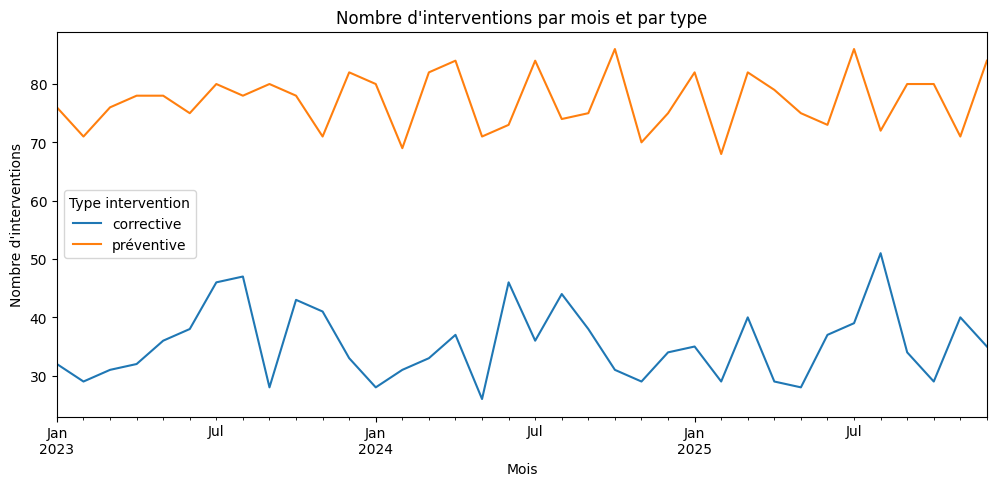

In [4]:
mensuel = df.groupby([df["Date intervention"].dt.to_period("M"), "Type intervention"]).size().unstack()

mensuel.plot(figsize=(12, 5))
plt.title("Nombre d'interventions par mois et par type")
plt.xlabel("Mois")
plt.ylabel("Nombre d'interventions")
plt.show()

**Lecture :**
- Les **préventives** restent stables (entre 70 et 86 par mois) : elles suivent un calendrier planifié.
- Les **correctives** ne montrent pas de tendance à la hausse ou à la baisse sur trois ans, mais des **pics qui reviennent chaque été** (juillet-août 2023, juin-août 2024, août 2025) : c'est une **saisonnalité**.
- Il y a plus de préventives que de correctives parce qu'elles sont programmées à intervalles fixes. Leur efficacité contre les pannes reste à démontrer (question 2).

## 2. Seasonality – Saisonnalité des pannes

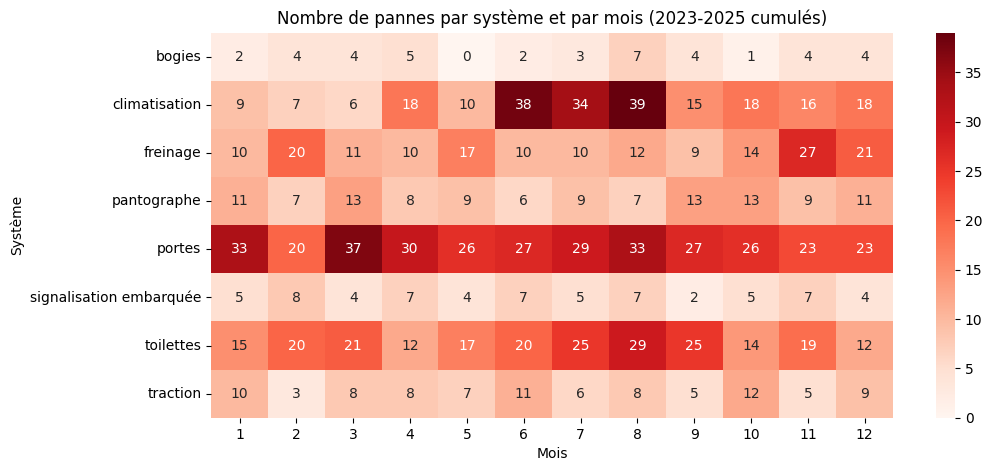

In [5]:
saison = pd.crosstab(cor["Système"], cor["Date intervention"].dt.month)

plt.figure(figsize=(11, 5))
sns.heatmap(saison, cmap="Reds", annot=True, fmt="d")
plt.title("Nombre de pannes par système et par mois (2023-2025 cumulés)")
plt.xlabel("Mois")
plt.ylabel("Système")
plt.show()

**Lecture :**
- **Climatisation : saisonnalité très nette.** 6 à 10 pannes par mois en hiver contre 34 à 39 de juin à août, soit environ quatre fois plus. C'est elle qui crée les pics d'été.
- **Freinage : saisonnalité inverse**, en hiver (novembre 27, décembre 21, février 20, contre environ 10 en été). Côté métier : givre, humidité, adhérence dégradée.
- **Toilettes : légère hausse en été** (25 à 29 de juillet à septembre), plausible avec la chaleur et la fréquentation des vacances.
- **Portes : pas de saisonnalité.** Elles sont élevées toute l'année : elles pèsent sur le **niveau** des pannes, pas sur les pics.

In [6]:
tab = pd.crosstab(df["Système"], df["Type intervention"])
tab["part_corrective_%"] = (tab["corrective"] / tab.sum(axis=1) * 100).round(1)
tab.sort_values("part_corrective_%", ascending=False)

Type intervention,corrective,préventive,part_corrective_%
Système,,,
climatisation,228,278,45.1
portes,334,566,37.1
traction,92,189,32.7
freinage,171,371,31.5
toilettes,229,554,29.2
pantographe,116,366,24.1
signalisation embarquée,65,273,19.2
bogies,40,181,18.1


**Lecture :**
- **En nombre**, les portes ont le plus de pannes (334).
- **En proportion**, la climatisation a la plus forte part de correctives (45 %) : près d'une intervention sur deux est une panne.
- Nuance : cette proportion dépend aussi de la fréquence des visites préventives. Un système visité moins souvent aura mécaniquement une part de correctives plus élevée.

**Conclusion opérationnelle :** le plan préventif de la climatisation, réparti sur toute l'année, n'empêche pas les pannes d'été. Une **campagne préventive ciblée au printemps** (avril-mai) pour la climatisation, et **à l'automne** pour le freinage, serait une recommandation naturelle.

## 3. MTTR, MDT and waiting time – Temps de réparation et d'immobilisation

- **MTTR** (Mean Time To Repair) : durée moyenne d'intervention, calculée sur les **correctives uniquement**. Inclure les préventives, courtes et planifiées, le ferait baisser artificiellement.
- **MDT** (Mean Down Time) : temps moyen d'immobilisation par panne. Il entre dans la disponibilité : A = MTBF / (MTBF + MDT).
- **Attente** = MDT − MTTR : temps perdu hors réparation (pièces, disponibilité d'une équipe, essais).

In [7]:
indicateurs = cor.groupby("Système").agg(
    nb_pannes=("Durée intervention (h)", "size"),
    MTTR_h=("Durée intervention (h)", "mean"),
    MDT_h=("Temps d'immobilisation (h)", "mean"),
).round(1)

indicateurs["attente_h"] = indicateurs["MDT_h"] - indicateurs["MTTR_h"]
indicateurs["part_attente_%"] = (indicateurs["attente_h"] / indicateurs["MDT_h"] * 100).round(0)
indicateurs.sort_values("MDT_h", ascending=False)

,nb_pannes,MTTR_h,MDT_h,attente_h,part_attente_%
Système,,,,,
bogies,40,7.6,19.6,12.0,61.0
traction,92,7.5,19.6,12.1,62.0
pantographe,116,3.4,18.5,15.1,82.0
freinage,171,3.9,16.7,12.8,77.0
climatisation,228,3.0,15.1,12.1,80.0
signalisation embarquée,65,2.6,14.8,12.2,82.0
portes,334,2.6,14.5,11.9,82.0
toilettes,229,1.4,11.8,10.4,88.0


**Lecture :**
- **Les plus longs à réparer** : bogies et traction, à égalité (MTTR ≈ 7,5 h).
- **Les plus immobilisants par panne** : bogies et traction (MDT ≈ 19,6 h), suivis du pantographe (18,5 h).
- **L'attente domine** : 10 à 15 h par panne quel que soit le système, alors que le MTTR va de 1,4 h à 7,6 h. L'attente ne dépend donc presque pas de la difficulté technique : c'est un **délai d'organisation**.
- Plus la réparation est courte, plus l'attente pèse en proportion : **88 %** du temps d'arrêt pour les toilettes, **62 %** pour la traction.
- Le **pantographe** a l'attente la plus longue en heures (≈ 15 h) : piste à creuser, peut-être un problème d'approvisionnement en pièces.

**Conclusion :** pour améliorer la disponibilité, réduire l'attente (stock, logistique, organisation) rapporte plus qu'accélérer les réparations.

In [8]:
# Temps total perdu par système : c'est ce qui compte pour l'exploitant
indicateurs["immo_totale_h"] = indicateurs["nb_pannes"] * indicateurs["MDT_h"]
indicateurs.sort_values("immo_totale_h", ascending=False)


,nb_pannes,MTTR_h,MDT_h,attente_h,part_attente_%,immo_totale_h
Système,,,,,,
portes,334,2.6,14.5,11.9,82.0,4843.0
climatisation,228,3.0,15.1,12.1,80.0,3442.8
freinage,171,3.9,16.7,12.8,77.0,2855.7
toilettes,229,1.4,11.8,10.4,88.0,2702.2
pantographe,116,3.4,18.5,15.1,82.0,2146.0
traction,92,7.5,19.6,12.1,62.0,1803.2
signalisation embarquée,65,2.6,14.8,12.2,82.0,962.0
bogies,40,7.6,19.6,12.0,61.0,784.0


**Le classement s'inverse :**
- **Par panne**, bogies et traction immobilisent le plus longtemps. **Au total**, ils arrivent en dernier (784 h et 1 803 h), car ils tombent rarement en panne.
- Les **portes** ont des pannes courtes (14,5 h) mais très fréquentes (334) : elles cumulent **4 843 h**, le plus gros total de la flotte.

Pour la disponibilité, **la fréquence des pannes pèse plus que leur gravité**.

## 4. Pareto – Quels systèmes concentrent les heures perdues ?

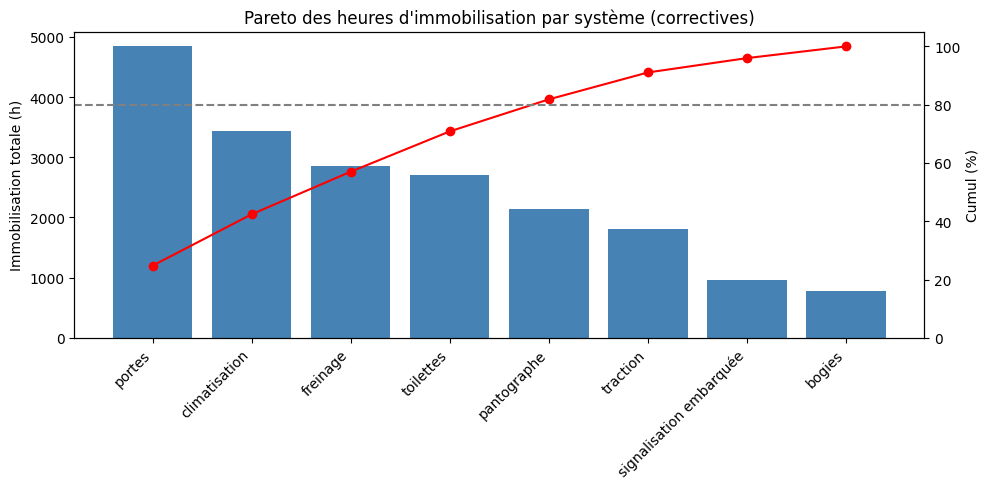

Système
portes                      24.8
climatisation               42.4
freinage                    57.0
toilettes                   70.9
pantographe                 81.8
traction                    91.1
signalisation embarquée     96.0
bogies                     100.0
Name: immo_totale_h, dtype: float64


In [9]:
pareto = indicateurs["immo_totale_h"].sort_values(ascending=False)
cumul_pct = pareto.cumsum() / pareto.sum() * 100

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(pareto.index, pareto.values, color="steelblue")
ax1.set_ylabel("Immobilisation totale (h)")
plt.xticks(rotation=45, ha="right")

ax2 = ax1.twinx()                                   # second axe vertical pour le cumul
ax2.plot(pareto.index, cumul_pct, color="red", marker="o")
ax2.axhline(80, color="grey", linestyle="--")       # repère des 80 %
ax2.set_ylabel("Cumul (%)")
ax2.set_ylim(0, 105)

plt.title("Pareto des heures d'immobilisation par système (correctives)")
plt.tight_layout()
plt.show()

print(cumul_pct.round(1))

**Lecture :** il faut **5 systèmes sur 8** pour atteindre 80 % des heures perdues (≈ 82 % avec le pantographe). Les deux premiers (portes et climatisation) n'en représentent qu'environ 42 %.

**La règle des 80/20 ne se vérifie pas** : les pertes sont dispersées. Ce n'est pas un échec de l'analyse mais un résultat : aucune action ciblée sur un seul système ne résoudra le problème de disponibilité. Comme l'attente est commune à tous les systèmes, c'est une **action transversale** (logistique, organisation) qui paiera le plus, complétée par des actions ciblées (portes, campagnes saisonnières).

## 5. MTBF – Temps moyen entre pannes

Le MTBF se calcule par couple **rame / système** : une panne de portes sur R001 et une autre sur R017 concernent deux équipements différents. Deux méthodes sont comparées :
- **Méthode 1 – moyenne des intervalles** : pour chaque couple, temps écoulé entre deux pannes consécutives, puis moyenne par système.
- **Méthode 2 – formule RAMS** : MTBF = temps total de fonctionnement / nombre de pannes, avec un temps total de 30 rames × période d'observation.

In [10]:
# Méthode 1 : intervalles entre pannes consécutives (même rame, même système)
cor["jours_depuis_panne"] = cor.groupby(["Matériel", "Système"])["Date intervention"].diff().dt.days

mtbf_1 = cor.groupby("Système")["jours_depuis_panne"].agg(["mean", "median", "count"]).round(0)
mtbf_1.sort_values("mean")


,mean,median,count
Système,,,
portes,88.0,62.0,304
toilettes,118.0,82.0,199
climatisation,128.0,90.0,198
freinage,157.0,109.0,141
pantographe,170.0,143.0,86
traction,250.0,234.0,64
signalisation embarquée,269.0,224.0,39
bogies,290.0,217.0,20


In [11]:
# Méthode 2 : temps total de fonctionnement / nombre de pannes
periode_jours = (df["Date intervention"].max() - df["Date intervention"].min()).days
nb_rames = df["Matériel"].nunique()

mtbf_2 = (nb_rames * periode_jours / cor.groupby("Système").size()).round(0)

comparaison_mtbf = pd.DataFrame({"methode_1_j": mtbf_1["mean"], "methode_2_j": mtbf_2})
comparaison_mtbf["ecart_%"] = ((comparaison_mtbf["methode_1_j"] / comparaison_mtbf["methode_2_j"] - 1) * 100).round(0)
comparaison_mtbf.sort_values("methode_2_j")

,methode_1_j,methode_2_j,ecart_%
Système,,,
portes,88.0,98.0,-10.0
toilettes,118.0,143.0,-17.0
climatisation,128.0,144.0,-11.0
freinage,157.0,192.0,-18.0
pantographe,170.0,283.0,-40.0
traction,250.0,357.0,-30.0
signalisation embarquée,269.0,505.0,-47.0
bogies,290.0,821.0,-65.0


**Contrôle de cohérence :** les deux méthodes donnent **le même classement**, des portes aux bogies. En revanche, la méthode 1 donne toujours moins, et l'écart grandit pour les systèmes qui tombent rarement en panne (≈ −10 % pour les portes, ≈ −65 % pour les bogies).

**Pourquoi ?** La méthode 1 ne voit pas une partie du temps de fonctionnement :
- entre le début de l'observation et la première panne ;
- entre la dernière panne et la fin de l'observation ;
- les couples rame/système avec une seule panne, ou aucune.

Ce phénomène s'appelle la **censure** des données. **La méthode 2 est retenue**, car elle compte tout le temps de fonctionnement. La méthode 1 garde un intérêt : elle montre la **dispersion** (pour les portes, une médiane de 62 j contre une moyenne de 88 j : la moitié des pannes se répètent en moins de deux mois).

**Limite :** la méthode 2 suppose un fonctionnement continu et compte en jours calendaires. En ferroviaire, le MTBF s'exprime plutôt en kilomètres ou en heures de service, absents ici.

**Lecture métier :** sur une même rame, les portes tombent en panne environ tous les 3 mois, les bogies environ tous les 2 ans et 3 mois.

## 6. Availability – Disponibilité

In [12]:
synthese = pd.DataFrame({
    "nb_pannes": indicateurs["nb_pannes"],
    "MTTR_h": indicateurs["MTTR_h"],
    "MDT_h": indicateurs["MDT_h"],
    "MTBF_j": mtbf_2,
})
synthese["MDT_j"] = synthese["MDT_h"] / 24     # même unité que le MTBF
synthese["dispo_%"] = (synthese["MTBF_j"] / (synthese["MTBF_j"] + synthese["MDT_j"]) * 100).round(3)

synthese.sort_values("dispo_%")

,nb_pannes,MTTR_h,MDT_h,MTBF_j,MDT_j,dispo_%
Système,,,,,,
portes,334,2.6,14.5,98.0,0.604167,99.387
climatisation,228,3.0,15.1,144.0,0.629167,99.565
freinage,171,3.9,16.7,192.0,0.695833,99.639
toilettes,229,1.4,11.8,143.0,0.491667,99.657
pantographe,116,3.4,18.5,283.0,0.770833,99.728
traction,92,7.5,19.6,357.0,0.816667,99.772
signalisation embarquée,65,2.6,14.8,505.0,0.616667,99.878
bogies,40,7.6,19.6,821.0,0.816667,99.901


In [13]:
# Une rame ne circule que si tous ses systèmes fonctionnent (systèmes en série) :
# les indisponibilités s'additionnent (approximation valable quand elles sont petites)
indispo_totale = (100 - synthese["dispo_%"]).sum()
print(f"Indisponibilité d'une rame due aux pannes : {indispo_totale:.2f} %")
print(f"Soit environ {indispo_totale / 100 * 365:.1f} jours par an et par rame")
print(f"Soit environ {indispo_totale / 100 * nb_rames:.1f} rame(s) en permanence à l'arrêt sur la flotte")

Indisponibilité d'une rame due aux pannes : 2.47 %
Soit environ 9.0 jours par an et par rame
Soit environ 0.7 rame(s) en permanence à l'arrêt sur la flotte


**Lecture :**
- Tous les systèmes dépassent **99 %** de disponibilité. Les **portes** sont les moins disponibles (99,39 %), ce qui confirme le Pareto ; les bogies les plus disponibles (99,90 %).
- Ces valeurs sont proches de 100 % parce qu'une panne immobilise environ une demi-journée (MDT de 0,5 à 0,8 jour), alors qu'il se passe des mois entre deux pannes.
- **Cela ne veut pas dire que tout va bien.** Une rame est un **système en série** : les indisponibilités s'additionnent. La disponibilité d'une rame face aux pannes tombe à **≈ 97,5 %**, soit **≈ 9 jours d'arrêt par an et par rame**, ou l'équivalent de **≈ 0,7 rame** en permanence à l'arrêt sur la flotte. Et les préventives, non comptées ici, immobilisent aussi les rames.

Chaque dixième de pourcent gagné sur un système compte pour la flotte entière.

## 7. Train-level analysis – Analyse par rame

In [14]:
periode_h = periode_jours * 24

par_rame = df.pivot_table(index="Matériel", columns="Type intervention",
                          values="Temps d'immobilisation (h)", aggfunc="sum")
par_rame["total_h"] = par_rame["corrective"] + par_rame["préventive"]
par_rame["nb_pannes"] = cor.groupby("Matériel").size()
par_rame["dispo_%"] = (100 - par_rame["total_h"] / periode_h * 100).round(2)

par_rame.sort_values("dispo_%").head(10)

Type intervention,corrective,préventive,total_h,nb_pannes,dispo_%
Matériel,,,,,
R018,1055.2,479.8,1535.0,63,94.16
R010,1030.6,453.4,1484.0,68,94.35
R015,936.3,443.1,1379.4,51,94.75
R013,840.2,465.8,1306.0,46,95.03
R001,844.1,414.1,1258.2,55,95.21
R002,768.1,476.3,1244.4,53,95.26
R028,759.4,480.2,1239.6,48,95.28
R004,791.9,445.3,1237.2,47,95.29
R017,749.0,436.7,1185.7,54,95.49


In [15]:
# Contrôle : les NaN d'immobilisation, ignorés dans les sommes, sont-ils concentrés sur certaines rames ?
df.groupby("Matériel")["Temps d'immobilisation (h)"].apply(lambda s: s.isna().sum()).sort_values(ascending=False).head()

Matériel
R001    6
R017    5
R025    5
R030    5
R019    5
Name: Temps d'immobilisation (h), dtype: int64

Au maximum 6 valeurs manquantes par rame, sur 100 à 150 interventions chacune : l'effet est négligeable et les totaux par rame sont fiables.

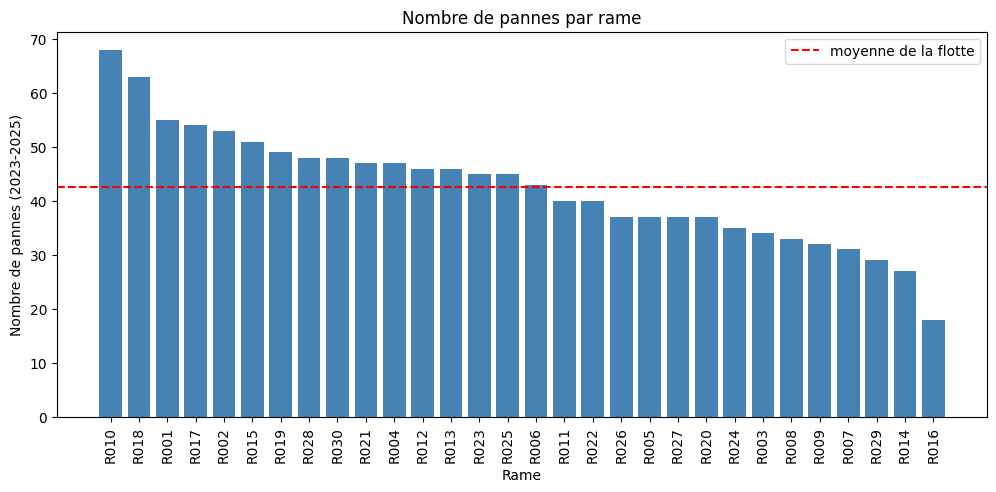

In [16]:
pannes = par_rame["nb_pannes"].sort_values(ascending=False)

plt.figure(figsize=(12, 5))
plt.bar(pannes.index, pannes.values, color="steelblue")
plt.axhline(pannes.mean(), color="red", linestyle="--", label="moyenne de la flotte")
plt.xticks(rotation=90)
plt.xlabel("Rame")
plt.ylabel("Nombre de pannes (2023-2025)")
plt.title("Nombre de pannes par rame")
plt.legend()
plt.show()

**Lecture :**
- **R010 (68 pannes) et R018 (63)** se détachent nettement de la moyenne de la flotte (≈ 42). Après elles, on passe à 55 et la baisse devient progressive.
- À l'autre extrémité, **R016** n'a que 18 pannes.
- L'écart entre la rame la plus et la moins fiable est d'environ **4**. Sans les extrêmes, la plupart des rames se situent entre 30 et 55 pannes, soit un facteur d'environ 1,8 : c'est beaucoup pour des rames du même type.

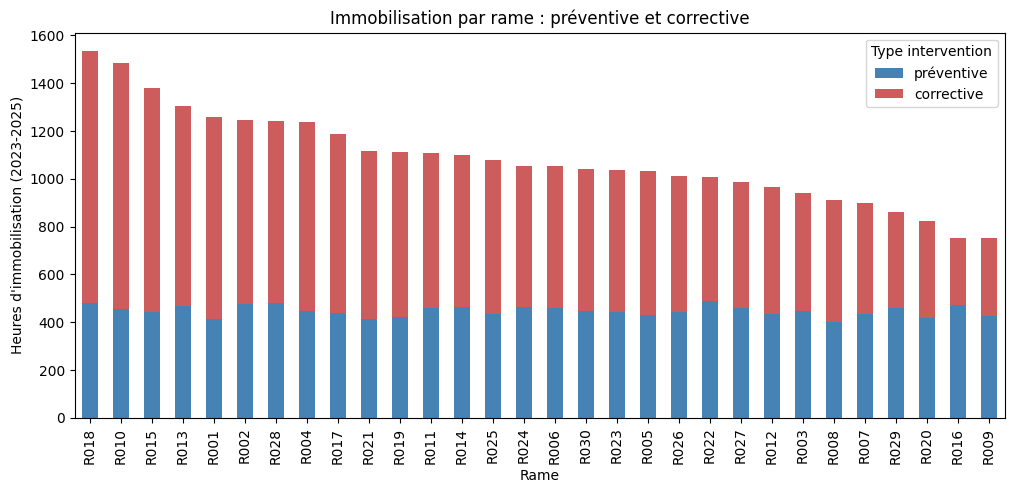

,mean,std,min,max,CV_%
Type intervention,,,,,
préventive,447.0,22.0,400.0,488.0,5.0
corrective,637.0,188.0,280.0,1055.0,30.0


In [17]:
vue = par_rame.sort_values("total_h", ascending=False)

vue[["préventive", "corrective"]].plot(kind="bar", stacked=True, figsize=(12, 5),
                                      color=["steelblue", "indianred"])
plt.xlabel("Rame")
plt.ylabel("Heures d'immobilisation (2023-2025)")
plt.title("Immobilisation par rame : préventive et corrective")
plt.xticks(rotation=90)
plt.show()

# Coefficient de variation (écart-type / moyenne) : dispersion comparable entre deux colonnes
variabilite = par_rame[["préventive", "corrective"]].agg(["mean", "std", "min", "max"]).T
variabilite["CV_%"] = (variabilite["std"] / variabilite["mean"] * 100).round(1)
variabilite.round(0)

**Lecture :** les heures de préventive sont presque identiques d'une rame à l'autre (400 à 488 h, **CV de 5 %**), car elles suivent le même calendrier. Les correctives varient fortement (280 à 1 055 h, **CV de 30 %**). Les écarts de disponibilité entre rames viennent donc des **pannes**, pas du plan de maintenance.

Question suivante : R010 et R018 souffrent-elles d'un système en particulier, ou de pannes réparties partout ?

In [18]:
comparaison = pd.DataFrame({
    "R010_R018_%": cor[cor["Matériel"].isin(["R010", "R018"])]["Système"].value_counts(normalize=True) * 100,
    "flotte_%": cor["Système"].value_counts(normalize=True) * 100,
}).round(1)
comparaison["ecart_pts"] = (comparaison["R010_R018_%"] - comparaison["flotte_%"]).round(1)
comparaison

,R010_R018_%,flotte_%,ecart_pts
Système,,,
bogies,0.8,3.1,-2.3
climatisation,19.8,17.9,1.9
freinage,12.2,13.4,-1.2
pantographe,12.2,9.1,3.1
portes,22.9,26.2,-3.3
signalisation embarquée,6.9,5.1,1.8
toilettes,15.3,18.0,-2.7
traction,9.9,7.2,2.7


**Lecture :** la répartition des pannes de R010 et R018 est très proche de celle de la flotte (écarts d'environ 3 points au maximum, dans le bruit avec ≈ 130 pannes). **Aucun système ne domine** : ces rames tombent plus souvent en panne sur l'ensemble de leurs systèmes. La cause est donc probablement propre à la rame (âge, historique, ligne parcourue, conditions d'exploitation), ce qui appelle une action globale (révision générale ou réaffectation) plutôt qu'une action sur un équipement.


## 8. Workload – Charge corrective des ateliers et équipes

Je me limite aux **correctives** : la charge préventive est planifiée et reflète le planning, pas un problème. La charge est mesurée par la **durée d'intervention** (temps de travail), pas par l'immobilisation.

**Limite :** les données ne disent rien de la **capacité** des ateliers (effectifs, horaires) : on peut montrer qui travaille le plus, pas qui est saturé.

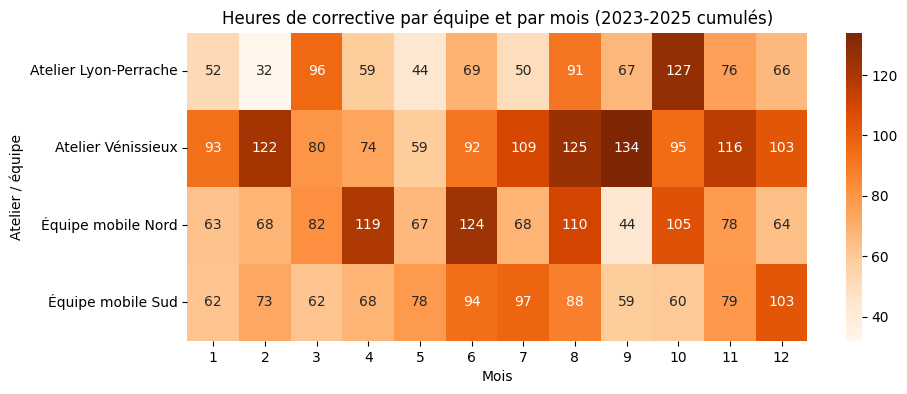

In [19]:
cor_mensuel = cor.pivot_table(index=cor["Date intervention"].dt.month, columns="Technicien",
                              values="Durée intervention (h)", aggfunc="sum")

plt.figure(figsize=(10, 4))
sns.heatmap(cor_mensuel.drop(columns="Inconnu", errors="ignore").T.round(0),
            annot=True, fmt=".0f", cmap="Oranges")
plt.title("Heures de corrective par équipe et par mois (2023-2025 cumulés)")
plt.xlabel("Mois")
plt.ylabel("Atelier / équipe")
plt.show()

**Lecture :** l'atelier de **Vénissieux** porte la plus grosse charge corrective sur la plupart des mois. La hausse estivale se voit chez **plusieurs** équipes à la fois : aucune n'absorbe seule le pic. Les valeurs cumulent trois ans : un écart de quelques dizaines d'heures entre deux mois reste du bruit.

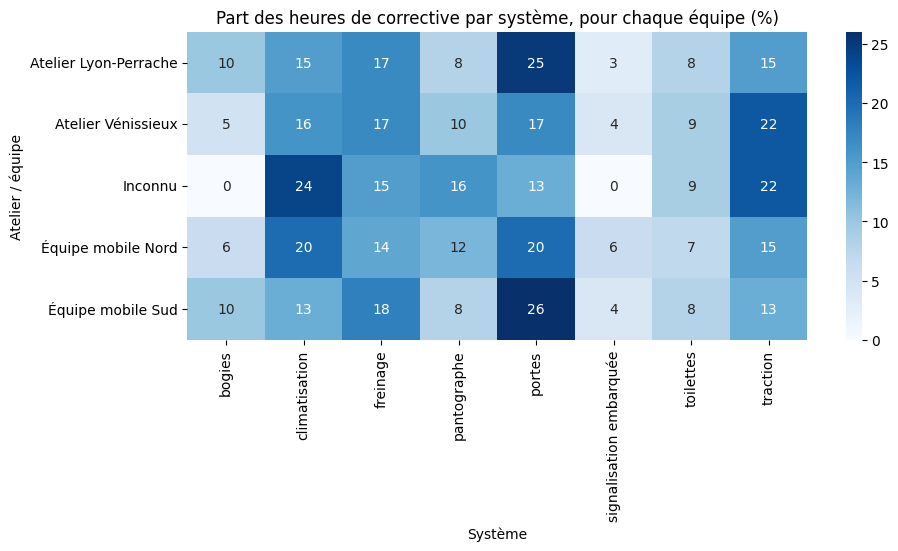

In [20]:
repartition = pd.crosstab(cor["Technicien"], cor["Système"],
                          values=cor["Durée intervention (h)"], aggfunc="sum",
                          normalize="index") * 100

plt.figure(figsize=(10, 4))
sns.heatmap(repartition.round(0), annot=True, fmt=".0f", cmap="Blues")
plt.title("Part des heures de corrective par système, pour chaque équipe (%)")
plt.xlabel("Système")
plt.ylabel("Atelier / équipe")
plt.show()

**Lecture : les équipes sont polyvalentes.** Chacune répare tous les systèmes, et aucune ne dépasse 26 % sur un seul. Les profils se ressemblent beaucoup : portes, traction, freinage et climatisation en tête partout. La ligne « Inconnu » repose sur trop peu de cas pour être interprétée.

Aucune équipe n'absorbe seule la saisonnalité d'un système, ce qui limite le risque d'organisation. La charge semble donc moins en cause que l'**approvisionnement** dans l'attente d'environ 12 h, une hypothèse que seules des données de stock permettraient de confirmer.

## 9. Weibull analysis – Les pannes relèvent-elles de l'usure ?

La loi de Weibull décrit le temps avant une panne. Son paramètre de forme **β** indique comment le risque évolue avec le temps :
- **β < 1** : pannes de jeunesse, le risque diminue ;
- **β ≈ 1** : pannes aléatoires, le risque est constant ;
- **β > 1** : usure, le risque augmente, ce qui justifie une maintenance préventive à intervalle fixe.

**Construction des durées (par couple rame/système) :**
- entre deux pannes consécutives : durée **observée** ;
- de la dernière panne à la fin de l'observation : durée **censurée** (la panne n'a pas encore eu lieu) ;
- couples sans aucune panne : toute la période est censurée ;
- du début de l'observation à la première panne : **exclue**, car la panne précédente (avant 2023) est inconnue.

**Hypothèses :** une réparation remet le système « comme neuf » ; les visites préventives ne remettent pas l'horloge à zéro dans ce calcul.

In [21]:
debut, fin = df["Date intervention"].min(), df["Date intervention"].max()

lignes = []
for (rame, systeme), g in cor.groupby(["Matériel", "Système"]):
    dates = g["Date intervention"].sort_values()
    for ecart in dates.diff().dt.days.dropna():                        # intervalles observés
        lignes.append({"Système": systeme, "duree": ecart, "observe": 1})
    lignes.append({"Système": systeme, "duree": (fin - dates.iloc[-1]).days, "observe": 0})   # censuré

# Couples rame/système sans aucune panne : toute la période est censurée
couples_avec_panne = set(zip(cor["Matériel"], cor["Système"]))
for rame in df["Matériel"].unique():
    for systeme in df["Système"].unique():
        if (rame, systeme) not in couples_avec_panne:
            lignes.append({"Système": systeme, "duree": (fin - debut).days, "observe": 0})

durees = pd.DataFrame(lignes)
durees["duree"] = durees["duree"].clip(lower=0.5)    # Weibull refuse les durées nulles

controle = durees.groupby("Système")["observe"].agg(total="count", observees="sum")
controle["censurees"] = controle["total"] - controle["observees"]
controle   # une durée censurée par rame (30) attendue pour chaque système


,total,observees,censurees
Système,,,
bogies,50,20,30
climatisation,228,198,30
freinage,171,141,30
pantographe,116,86,30
portes,334,304,30
signalisation embarquée,69,39,30
toilettes,229,199,30
traction,94,64,30


In [22]:
resultats = []
for systeme, g in durees.groupby("Système"):
    wf = WeibullFitter().fit(g["duree"], event_observed=g["observe"])
    s = wf.summary
    resultats.append({
        "Système": systeme,
        "beta": wf.rho_,
        "beta_bas_95": s.loc["rho_", "coef lower 95%"],
        "beta_haut_95": s.loc["rho_", "coef upper 95%"],
        "eta_jours": wf.lambda_,
        "vie_moyenne_j": wf.lambda_ * gamma(1 + 1 / wf.rho_),
    })

weibull = pd.DataFrame(resultats).set_index("Système").round(2)

# Contrôle de cohérence avec le MTBF (méthode 2)
weibull["MTBF_methode2_j"] = mtbf_2
weibull["ecart_%"] = ((weibull["vie_moyenne_j"] / weibull["MTBF_methode2_j"] - 1) * 100).round(0)
weibull.sort_values("beta")

,beta,beta_bas_95,beta_haut_95,eta_jours,vie_moyenne_j,MTBF_methode2_j,ecart_%
Système,,,,,,,
bogies,0.69,0.42,0.96,1685.62,2166.23,821.0,164.0
signalisation embarquée,0.91,0.68,1.15,615.57,642.52,505.0,27.0
freinage,1.00,0.87,1.13,193.21,193.41,192.0,1.0
pantographe,1.02,0.85,1.20,266.33,263.76,283.0,-7.0
toilettes,1.03,0.92,1.14,146.85,145.25,143.0,2.0
climatisation,1.04,0.92,1.15,145.36,143.33,144.0,-0.0
portes,1.06,0.97,1.15,98.53,96.27,98.0,-2.0
traction,1.13,0.91,1.35,394.26,377.29,357.0,6.0


**1. Cohérence avec le MTBF :** pour six systèmes, la vie moyenne Weibull concorde avec le MTBF à quelques pourcents près : l'ajustement est fiable. Pour la **signalisation** (≈ +27 %) et surtout les **bogies** (≈ ×2,6), l'écart est trop grand : ce sont les systèmes avec le moins de pannes observées (39 et 20), et l'estimation devient instable.

**2. Forme (β) :**
- Pour la signalisation, le freinage, le pantographe, les toilettes, la climatisation et les portes, β est proche de 1 (0,91 à 1,06) et **l'intervalle à 95 % contient 1** : leurs pannes ne se distinguent pas de pannes aléatoires.
- **Traction** : β = 1,13, mais l'intervalle (0,91 à 1,35) contient 1 : une légère usure est possible, **non démontrée**.
- **Bogies** : β = 0,69 avec tout l'intervalle sous 1. Je ne retiens pas l'idée de pannes de jeunesse : l'estimation est incohérente avec le MTBF, repose sur 20 pannes, et le mélange de rames hétérogènes (certaines plus fragiles) fait baisser β artificiellement.
*ntre deux pannes en ignorant les visites préventives. *3. Interprétation :** conclure que « la préventive à intervalle fixe est inutile » serait une erreur.
- **L'horloge n'est pas la bonne** : on mesure le temps eSi une visite remet le système en état, l'usure se mesure depuis la dernière visite. Une préventive efficace **masque** donc l'usure dans ce calcul.
- **La climatisation le confirme** : β ≈ 1 malgré une forte saisonnalité. Ses pannes dépendent de la contrainte extérieure (la chaleur), pas de l'âge, ce que Weibull ne peut pas voir. La campagne de printemps reste justifiée, déclenchée par la saison et non par l'âge.

**Conclusion :** analysés entre deux pannes, aucun système ne présente d'usure démontrée. L'effet du temps écoulé **depuis la dernière visite préventive** sera testé directement dans le notebook de modélisation.

## 10. Summary – Synthèse de l'exploration

### Résultats
**Q1 – Fiabilité**
- **Les portes concentrent le plus d'heures perdues** : 4 843 h (≈ 25 % du total), à cause de leur fréquence de panne (334 pannes, MTBF ≈ 98 jours par rame), pas de leur gravité (MDT ≈ 14,5 h).
- **Pas de règle des 80/20** : 5 systèmes sur 8 pour atteindre 80 % des heures perdues.
- **Fréquence et gravité s'opposent** : bogies et traction sont les plus longs à réparer (MTTR ≈ 7,5 h) mais tombent rarement en panne (MTBF de 357 à 821 jours).
- **Fortes disparités entre rames** : de 18 à 68 pannes. Les écarts viennent des correctives (CV 30 % contre 5 % pour les préventives). R010 et R018 sont pénalisées sur tous leurs systèmes.

**Q2 – Maintenance préventive**
- Une corrective immobilise **≈ 3 fois plus longtemps** qu'une préventive, et de façon moins prévisible.
- **Deux saisonnalités** : climatisation en été (≈ ×4), freinage en hiver. Le plan préventif actuel, réparti sur l'année, n'empêche pas ces pics.
- **Weibull** : aucune usure démontrée entre deux pannes (β ≈ 1). L'effet du retard de préventive est testé dans le notebook 3.
**Q3 – Organisation**
- **L'attente domine le temps d'arrêt** : 10 à 15 h par panne quel que soit le système, soit 60 à 90 % de l'immobilisation.
- **Équipes polyvalentes** : aucune n'absorbe seule une saisonnalité ; l'approvisionnement semble plus en cause que la charge.

**Disponibilité :** chaque système dépasse 99 %, mais une rame (systèmes en série) tombe à **≈ 97,5 %**, soit ≈ 9 jours d'arrêt par an et par rame (hors préventives).

### Recommandations (par ordre d'impact attendu)
1. **Réduire l'attente** (stock de pièces, délais d'approvisionnement, créneaux atelier) : levier transversal, sur tous les systèmes.
2. **Fiabiliser les portes**, premier système en heures perdues.
3. **Campagnes préventives saisonnières** : climatisation au printemps, freinage à l'automne.
4. **Examiner R010 et R018 dans leur ensemble** (âge, historique de révisions, affectation) pour décider d'une révision générale ou d'une réaffectation.
5. **Compléter la collecte** : stocks et délais de pièces, kilométrage, capacité des ateliers, contrôles à la saisie.

### Limites
- Données synthétiques.
- MTBF en jours calendaires, faute de kilométrage ou d'heures de service.
- 2 à 3 % de valeurs manquantes sur la durée, l'immobilisation et le coût, ignorées dans les calculs.
- Cause de l'attente supposée mais non démontrée (aucune donnée de stock) ; capacité des ateliers inconnue.
- Weibull : hypothèse « réparé comme neuf », visites préventives non prises en compte.

**Suite :** notebook 3, prédiction d'une panne à 30 jours et effet du retard de maintenance préventive.